# Velocity and pressure gradient statistics (question 6)

**Assignment:** *Determine the statistics of (you may use linear wave theory):*
- *a. velocity near the bed, and maximum pressure gradient near the bed from the time series.*
- *b. velocity near the surface.*

**Given:** water depth $h = 25$ m, significant wave height $H_s = 7$ m, $\rho = 1025$ kg/m³, $g = 9.81$ m/s².

**Spectrum (taken from Wave Question 3, not chosen again):** JONSWAP with $ka = 0.25$ → $T_p = 7.72$ s ($f_p = 0.1295$ Hz), $\gamma = 3.3$, $\sigma = 0.07$ ($f \le f_p$) / $0.09$ ($f > f_p$), $A_\gamma = 1 - 0.287\ln\gamma = 0.6573$. In the setup cell $T_p$ is recomputed with exactly the same formulas as in Wave Question 3, and checked against that value.

**Approach:** a random-phase time series of the surface elevation is built from the spectrum. With linear wave theory, every component is transferred to velocity, pressure and pressure gradient at the required depth. The statistics then follow from the resulting time series.

**Assumptions:**
- **Current neglected:** the current velocity $U = 1.5$ m/s from the table is neglected. The waves are treated as if there is no current, so there is no Doppler shift and no current added to the velocity.
- **Fixed amplitudes:** every component has the deterministic amplitude $a_i = \sqrt{2E(f_i)\Delta f}$. Only the phases are random (no random amplitudes).
- **Long-crested waves** that all travel in the $+x$ direction, evaluated at $x = 0$.
- **Linear wave theory**, valid up to $z = 0$. "Near the bed" is taken as $z = -h$, i.e. just outside the wave boundary layer.

In [1]:
#Import the necessary packages
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
from scipy.signal import welch


#Define the given parameters (assignment)
H_DEPTH = 25.0     #water depth h [m]
HS      = 7.0      #significant wave height [m]
RHO     = 1025.0   #water density [kg/m3]
G       = 9.81     #gravitational acceleration [m/s2]


#Define the spectrum parameters (same as Wave Question 3)
KA      = 0.25                  #wave steepness ka [-]
GAMMA   = 3.3                   #JONSWAP peak enhancement factor [-]
SIGMA_A, SIGMA_B = 0.07, 0.09   #JONSWAP peak width for f <= fp and f > fp [-]


#Define the time series parameters
D      = 1800.0     #duration of the time series [s]
DT     = 0.1        #time step [s]
F_MAX  = 1.0        #highest frequency component [Hz]
SEED   = 1          #seed for the random phases [-]
N_SEED = 10         #number of seeds for the seed check [-]
BLOCK  = 200        #number of components per block in the synthesis [-]


#Define the folder where the figures are saved (next to this notebook)
OUT_DIR = Path(".")


#Create the plot style
def style(ax, title):
    ax.set_title(title)
    ax.grid(True, color="0.88", lw=0.6)

    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


#Define a function for the Pierson-Moskowitz spectrum, written in Hs and fp
def E_pm(f, hs, fp):
    return 5 / 16 * hs**2 * fp**4 * f**-5 * np.exp(-5 / 4 * (fp / f)**4) #[m2/Hz]


#Define a function for the JONSWAP spectrum: PM shape x peak enhancement, normalised with A_gamma
def E_jonswap(f, hs, fp, gamma=GAMMA, sa=SIGMA_A, sb=SIGMA_B):
    a_gamma = 1 - 0.287 * np.log(gamma)
    sigma = np.where(f <= fp, sa, sb)
    peak = gamma ** np.exp(-(f - fp)**2 / (2 * sigma**2 * fp**2))
    return a_gamma * E_pm(f, hs, fp) * peak #[m2/Hz]


#Define a function that solves the dispersion relation w^2 = g k tanh(kh) for k with Newton-Raphson
#The first guess is exact in deep and in shallow water, so only a few iterations are needed
def wave_number(omega, h=H_DEPTH, tol=1e-12, n_iter=50):
    k0 = omega**2 / G
    k = k0 / np.sqrt(np.tanh(k0 * h))

    for _ in range(n_iter):
        F  = G * k * np.tanh(k * h) - omega**2
        dF = G * np.tanh(k * h) + G * k * h / np.cosh(k * h)**2
        dk = F / dF
        k  = k - dk
        if np.max(np.abs(dk / k)) < tol:
            break

    return k #[rad/m]


#Calculate Tp exactly as in Wave Question 3: ka -> k -> full dispersion relation
a_assumed = HS / 2                                                #[m]
k_p       = KA / a_assumed                                        #[rad/m]
Tp        = 2 * np.pi / np.sqrt(G * k_p * np.tanh(k_p * H_DEPTH)) #[s]
fp        = 1 / Tp                                                #[Hz]
A_GAMMA   = 1 - 0.287 * np.log(GAMMA)                             #[-]


#Print the results
print(f"Tp = {Tp:.2f} s,  fp = {fp:.4f} Hz,  gamma = {GAMMA},  sigma = {SIGMA_A}/{SIGMA_B},  A_gamma = {A_GAMMA:.4f}")
print("Same as Wave Question 3 (Tp = 7.72 s, A_gamma = 0.6573):", round(Tp, 2) == 7.72 and round(A_GAMMA, 4) == 0.6573)

Tp = 7.72 s,  fp = 0.1295 Hz,  gamma = 3.3,  sigma = 0.07/0.09,  A_gamma = 0.6573
Same as Wave Question 3 (Tp = 7.72 s, A_gamma = 0.6573): True


## Step 1 — Time series of the surface elevation

The surface elevation is the sum of many harmonic components with random phases (L5, appendix slides 2 and 4):

$$\eta(t) = \sum_i a_i \cos(2\pi f_i t + \alpha_i), \qquad a_i = \sqrt{2E(f_i)\,\Delta f}.$$

- **Frequencies:** $f_i = i\,\Delta f$, from $\Delta f$ up to $f_{max} = 1.0$ Hz.
- **Duration and resolution:** $D = 1800$ s and $\Delta f = 1/D$. The series then does not repeat itself within $D$.
- **Time step:** $\Delta t = 0.1$ s, which satisfies $\Delta t < 1/(2f_{max}) = 0.5$ s (Nyquist).
- **Phases:** $\alpha_i$ is uniformly distributed on $[0, 2\pi)$, drawn with a fixed seed (`np.random.default_rng`), so the result is reproducible.
- **Amplitudes:** fixed and not random (see the assumptions above).

There are $N = 1800$ components and $18000$ time steps. A full $N \times N_t$ matrix would therefore cost about 260 MB. The synthesis is done **in blocks of components**, so only a small part of that matrix is in memory at a time.

In [2]:
#Create the frequency grid, the spectrum and the component amplitudes
DF  = 1 / D                                        #frequency step [Hz]
f_i = np.arange(1, int(round(F_MAX / DF)) + 1) * DF #[Hz]
E_i = E_jonswap(f_i, HS, fp)                       #[m2/Hz]
a_i = np.sqrt(2 * E_i * DF)                        #[m]
w_i = 2 * np.pi * f_i                              #[rad/s]


#Create the time vector
t = np.arange(0, D, DT) #[s]


#Define a function that draws the random phases for a given seed
def phases(seed, n=len(f_i)):
    return np.random.default_rng(seed).uniform(0, 2 * np.pi, n) #[rad]


#Define a function that adds up all components in blocks: sum c_cos cos(wt + alpha) + c_sin sin(wt + alpha)
#Every row of c_cos and c_sin belongs to one signal, so several signals are built at once
def synthesise(c_cos, c_sin, alpha, t=t, omega=w_i, block=BLOCK):
    out = np.zeros((c_cos.shape[0], len(t)))

    for j in range(0, len(omega), block):
        s = slice(j, j + block)
        theta = np.outer(omega[s], t) + alpha[s, None]
        out += c_cos[:, s] @ np.cos(theta) + c_sin[:, s] @ np.sin(theta)

    return out


#Print the results
print(f"Delta f = 1/D = {DF:.6f} Hz,  N components = {len(f_i)},  f = {f_i[0]:.6f} ... {f_i[-1]:.3f} Hz")
print(f"Delta t = {DT} s,  N time steps = {len(t)},  t = 0 ... {t[-1]:.1f} s")

Delta f = 1/D = 0.000556 Hz,  N components = 1800,  f = 0.000556 ... 1.000 Hz
Delta t = 0.1 s,  N time steps = 18000,  t = 0 ... 1799.9 s


## Step 2 — Linear wave theory per component

Each component $i$ has its own wave number. It follows from the dispersion relation (L3/L4),

$$\omega_i^2 = g k_i \tanh(k_i h),$$

which is solved for $k_i$ with Newton–Raphson (vectorised over all components).

**Phase convention.** A component travelling in the $+x$ direction is written as

$$\eta_i(x,t) = a_i\cos(\omega_i t - k_i x + \alpha_i).$$

This is the same wave as $a_i\cos(k_i x - \omega_i t - \alpha_i)$. At $x = 0$ it reduces to $a_i\cos(2\pi f_i t + \alpha_i)$, the form used in Step 1. All other quantities use **the same** $a_i$, $f_i$ and $\alpha_i$, so they are in phase with $\eta$. With $\theta_i = \omega_i t - k_i x + \alpha_i$:

$$u(z,t) = \sum_i a_i \omega_i \frac{\cosh k_i(z+h)}{\sinh k_i h} \cos\theta_i,$$

$$p_d(z,t) = \sum_i \rho g\, K_{p,i}(z)\, a_i \cos\theta_i, \qquad K_{p,i}(z) = \frac{\cosh k_i(z+h)}{\cosh k_i h}.$$

The velocity is positive (in the wave direction) under a crest, as it should be.

In [3]:
#Solve the dispersion relation for every component
k_i = wave_number(w_i) #[rad/m]


#Check the dispersion relation and the peak wave number
res_disp = np.max(np.abs(G * k_i * np.tanh(k_i * H_DEPTH) - w_i**2) / w_i**2)
k_at_fp  = wave_number(np.array([2 * np.pi * fp]))[0]


#Print the results
print(f"Max relative residual of the dispersion relation: {res_disp:.1e}")
print(f"k at fp = {k_at_fp:.4f} rad/m  (Wave Question 3: k = {k_p:.4f} rad/m)")
print(f"kh range: {k_i[0] * H_DEPTH:.4f} (f = {f_i[0]:.4f} Hz) ... {k_i[-1] * H_DEPTH:.1f} (f = {f_i[-1]:.1f} Hz)")

Max relative residual of the dispersion relation: 4.4e-16
k at fp = 0.0714 rad/m  (Wave Question 3: k = 0.0714 rad/m)
kh range: 0.0056 (f = 0.0006 Hz) ... 100.6 (f = 1.0 Hz)


## Step 3 — Pressure gradient near the bed

Differentiating the pressure with respect to $x$ gives, per component ($\partial\cos\theta_i/\partial x = k_i\sin\theta_i$):

$$\frac{\partial p_d}{\partial x}(z,t) = \sum_i \rho g\, K_{p,i}(z)\, a_i k_i \sin\theta_i.$$

**Check with the linearised Euler equation** (L1/L2):

$$\frac{\partial u}{\partial t} = -\frac{1}{\rho}\frac{\partial p}{\partial x}.$$

$\partial u/\partial t$ is computed **independently** from the velocity time series: (1) numerically, with central differences (`np.gradient`), and (2) analytically per component, $-\sum_i a_i\omega_i^2 \frac{\cosh k_i(z+h)}{\sinh k_i h}\sin\theta_i$. The two agree because the dispersion relation gives $\omega_i^2/\sinh k_i h = g k_i/\cosh k_i h$.

In [4]:
#Define a function with the linear transfer coefficients at depth z (multiply with a_i to get the amplitude)
def transfer(z, k=k_i, w=w_i, h=H_DEPTH):
    ch = np.cosh(k * (z + h))
    sh = np.sinh(k * (z + h))

    return {"u":    w * ch / np.sinh(k * h),             #horizontal velocity, x cos(theta) [1/s]
            "w":    -w * sh / np.sinh(k * h),            #vertical velocity, x sin(theta) [1/s]
            "dpdx": RHO * G * k * ch / np.cosh(k * h),   #horizontal pressure gradient, x sin(theta) [Pa/m2]
            "dpdz": RHO * G * k * sh / np.cosh(k * h),   #vertical dynamic pressure gradient, x cos(theta) [Pa/m2]
            "dudt": -w**2 * ch / np.sinh(k * h)}         #horizontal acceleration, x sin(theta) [1/s2]


#Calculate the transfer coefficients near the bed and near the surface
Z_BED, Z_SURF = -H_DEPTH, 0.0 #[m]
T_bed  = transfer(Z_BED)
T_surf = transfer(Z_SURF)


#Define a function that builds all time series for one seed
#For every signal: (coefficient of cos(theta), coefficient of sin(theta))
def build_series(seed):
    alpha = phases(seed)
    zero  = np.zeros_like(a_i)

    signals = {"eta":      (a_i,                 zero),
               "u_bed":    (a_i * T_bed["u"],    zero),
               "u_surf":   (a_i * T_surf["u"],   zero),
               "dpdx_bed": (zero,                a_i * T_bed["dpdx"]),
               "dudt_an":  (zero,                a_i * T_bed["dudt"]),
               "w_bed":    (zero,                a_i * T_bed["w"]),
               "w_surf":   (zero,                a_i * T_surf["w"]),
               "dpdz_bed": (a_i * T_bed["dpdz"], zero)}

    c_cos = np.array([c for c, s in signals.values()])
    c_sin = np.array([s for c, s in signals.values()])
    out = dict(zip(signals, synthesise(c_cos, c_sin, alpha)))

    out["speed_surf"] = np.sqrt(out["u_surf"]**2 + out["w_surf"]**2) #[m/s]
    return out


#Build the time series for the main seed
ts = build_series(SEED)


#Calculate du/dt numerically from the velocity and du/dt from the Euler equation (-1/rho dp/dx)
dudt_num   = np.gradient(ts["u_bed"], DT) #[m/s2]
dudt_euler = -ts["dpdx_bed"] / RHO        #[m/s2]


#Calculate the maximum deviations (without the one-sided end points of np.gradient)
inner   = slice(1, -1)
dev_an  = np.max(np.abs(ts["dudt_an"] - dudt_euler))                 #[m/s2]
dev_num = np.max(np.abs(dudt_num[inner] - dudt_euler[inner]))        #[m/s2]
scale   = np.max(np.abs(dudt_euler))                                 #[m/s2]


#Print the results
print(f"max |du/dt|                       = {scale:.4f} m/s2")
print(f"max |du/dt (analytic) + dp/dx/rho| = {dev_an:.1e} m/s2  ({100 * dev_an / scale:.1e} % of max)")
print(f"max |du/dt (numeric)  + dp/dx/rho| = {dev_num:.1e} m/s2  ({100 * dev_num / scale:.2f} % of max)")

max |du/dt|                       = 1.2193 m/s2
max |du/dt (analytic) + dp/dx/rho| = 2.3e-15 m/s2  (1.9e-13 % of max)
max |du/dt (numeric)  + dp/dx/rho| = 1.4e-03 m/s2  (0.12 % of max)


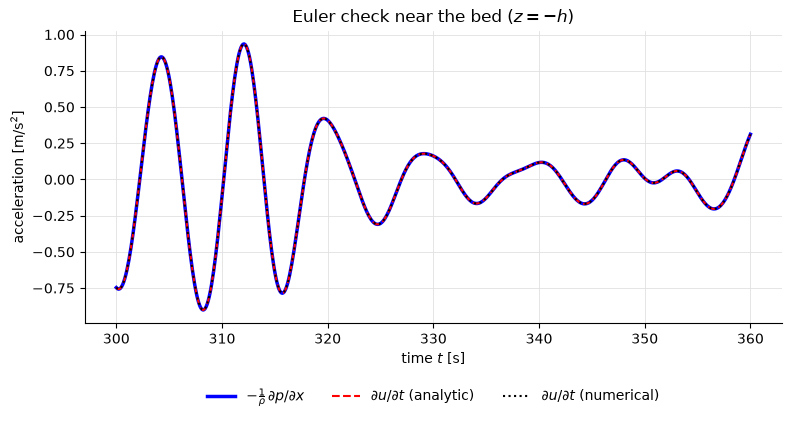

In [5]:
#Select a window of 60 s
win = (t >= 300) & (t <= 360)


#Plot -1/rho dp/dx against du/dt (analytic and numerical)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(t[win], dudt_euler[win], "-", color='b', lw=2.5, label=r"$-\frac{1}{\rho}\,\partial p/\partial x$")
ax.plot(t[win], ts["dudt_an"][win], "--", color='r', lw=1.5, label=r"$\partial u/\partial t$ (analytic)")
ax.plot(t[win], dudt_num[win], ":", color="k", lw=1.5, label=r"$\partial u/\partial t$ (numerical)")

ax.set_xlabel(r"time $t$ [s]")
ax.set_ylabel(r"acceleration [m/s$^2$]")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
style(ax, r"Euler check near the bed ($z = -h$)")
plt.savefig(OUT_DIR / "wave6_euler_check.png", dpi=300, bbox_inches="tight")
plt.show()

The three lines lie on top of each other. The analytic $\partial u/\partial t$ matches $-\frac{1}{\rho}\partial p/\partial x$ to machine precision. The numerical derivative deviates by only a small fraction of a percent, which is the truncation error of the central difference ($\sim(\omega\Delta t)^2/6$). **The pressure gradient is therefore consistent with the velocity.**

**Vertical velocity and vertical pressure gradient.** For completeness, the vertical components follow from the same potential:

$$w(z,t) = -\sum_i a_i \omega_i \frac{\sinh k_i(z+h)}{\sinh k_i h}\sin\theta_i, \qquad \frac{\partial p_d}{\partial z}(z,t) = \sum_i \rho g\, a_i k_i \frac{\sinh k_i(z+h)}{\cosh k_i h}\cos\theta_i.$$

The minus sign in $w$ follows from the kinematic surface condition $w(z=0) = \partial\eta/\partial t$: the water moves up while the surface rises. At the bed $\sinh k_i(z+h) = \sinh 0 = 0$, so **$w = 0$ and $\partial p_d/\partial z = 0$ at $z = -h$**. That is the impermeable-bed condition. It is consistent with the vertical Euler equation $\partial w/\partial t = -\frac{1}{\rho}\partial p_d/\partial z$. The total vertical gradient at the bed is then only the hydrostatic part, $\partial p/\partial z = -\rho g$, which is constant in time. "The pressure gradient near the bed" in part a is therefore the **horizontal** gradient $\partial p/\partial x$. Both statements are checked below, together with $w(z=0) = \partial\eta/\partial t$.

In [6]:
#Calculate the maximum of w and dp_d/dz at the bed (should be zero)
max_w_bed    = np.max(np.abs(ts["w_bed"]))    #[m/s]
max_dpdz_bed = np.max(np.abs(ts["dpdz_bed"])) #[Pa/m]


#Calculate d(eta)/dt numerically and compare with w at the surface (kinematic surface condition)
deta_dt   = np.gradient(ts["eta"], DT)                          #[m/s]
dev_kin   = np.max(np.abs(ts["w_surf"][inner] - deta_dt[inner])) #[m/s]
max_wsurf = np.max(np.abs(ts["w_surf"]))                        #[m/s]


#Print the results
print(f"max |w| at the bed          = {max_w_bed:.1e} m/s")
print(f"max |dp_d/dz| at the bed    = {max_dpdz_bed:.1e} Pa/m   (hydrostatic part: -rho g = {-RHO * G:.0f} Pa/m, constant)")
print(f"max |w(z=0) - d(eta)/dt|    = {dev_kin:.1e} m/s   ({100 * dev_kin / max_wsurf:.2f} % of max |w(z=0)| = {max_wsurf:.2f} m/s)")

max |w| at the bed          = 0.0e+00 m/s
max |dp_d/dz| at the bed    = 0.0e+00 Pa/m   (hydrostatic part: -rho g = -10055 Pa/m, constant)
max |w(z=0) - d(eta)/dt|    = 5.9e-02 m/s   (0.89 % of max |w(z=0)| = 6.64 m/s)


$w$ and $\partial p_d/\partial z$ are exactly zero at the bed, so at $z = -h$ only $u$ and $\partial p/\partial x$ vary in time. $w(z=0)$ matches $\partial\eta/\partial t$ within about 1 %. The remaining difference is the error of the numerical derivative for the short components (up to 1 Hz, where $\omega\Delta t = 0.63$), which are still strong at the surface. **The vertical velocity is consistent with the surface elevation.**

## Step 4 — Statistics near the bed and near the surface

- **Near the bed:** $z = -h$ (part a: $u$ and $\partial p/\partial x$). Here $\cosh k_i(z+h) = 1$, so the transfer factors are $\omega_i/\sinh k_i h$ for $u$ and $\rho g k_i/\cosh k_i h$ for $\partial p/\partial x$. The vertical velocity is zero here (Step 3), so $u$ is the complete velocity at the bed.
- **Near the surface:** $z = 0$ (part b). Here the factor for $u$ is $\omega_i\coth k_i h$ and for $w$ it is $\omega_i$. Because $\coth k_i h \approx 1$ for all but the longest components, $w$ is almost as large as $u$, so it is **not negligible** near the surface. $w$ lags $u$ by 90°: $u$ is largest under the crest and trough, $w$ in between. The magnitude of the velocity vector $|\mathbf{u}| = \sqrt{u^2 + w^2}$ is therefore also given. Linear wave theory is only defined **up to the still water level $z = 0$**. The velocity in the crest, above $z = 0$, is not described by it. The real velocity under a high crest is therefore somewhat larger than the value computed here, and extrapolating the formula above $z = 0$ (where $\cosh$ grows exponentially) would overestimate it at high frequencies.

**Statistics of each time series:**
- mean,
- standard deviation (= rms, because the mean is ≈ 0),
- maximum and minimum,
- **significant value**: the mean of the highest 1/3 of the peaks, where a peak is the maximum between two successive zero up-crossings.

For comparison, the significant value is also given as $2\sigma$. That is the expected value for a narrow-banded Gaussian (Rayleigh) process, analogous to $H_s = 4\sigma_\eta = 2 \cdot 2\sigma_\eta$. Linear theory gives a symmetric signal, so the negative side has the same statistics. The magnitude $\sqrt{u^2+w^2}$ is always positive and has no zero crossings, so only its mean, standard deviation and maximum are given.

In [7]:
#Define a function that finds the peaks: the maximum between two successive zero up-crossings
def peaks(x):
    x = x - x.mean()
    up = np.where((x[:-1] < 0) & (x[1:] >= 0))[0] + 1
    return np.array([x[i0:i1].max() for i0, i1 in zip(up[:-1], up[1:])])


#Define a function for the significant value: mean of the highest 1/3 of the peaks
def significant(x):
    p = np.sort(peaks(x))[::-1]
    return p[: len(p) // 3].mean()


#Define a function that returns all statistics of one time series
#An always-positive magnitude has no zero crossings, so it gets no peak statistics
def stats(x, oscillating=True):
    out = {"mean": x.mean(), "std (rms)": x.std(), "max": x.max(), "min": x.min(),
           "significant (1/3 peaks)": np.nan, "2 std": np.nan, "N peaks": np.nan}

    if oscillating:
        out["significant (1/3 peaks)"] = significant(x)
        out["2 std"]   = 2 * x.std()
        out["N peaks"] = len(peaks(x))

    return out


#Define the quantities and their labels
names = {"eta":        "eta [m]",
         "u_bed":      "u near bed, z = -h [m/s]",
         "dpdx_bed":   "dp/dx near bed, z = -h [Pa/m]",
         "u_surf":     "u near surface, z = 0 [m/s]",
         "w_surf":     "w near surface, z = 0 [m/s]",
         "speed_surf": "sqrt(u2+w2) near surface, z = 0 [m/s]"}


#Create a panda with the statistics of all quantities and print it out
table = pd.DataFrame({label: stats(ts[key], key != "speed_surf") for key, label in names.items()}).T
table.style.format(precision=3, na_rep="-").format("{:.0f}", subset=["N peaks"], na_rep="-")

,mean,std (rms),max,min,significant (1/3 peaks),2 std,N peaks
eta [m],0.000,1.752,6.826,-5.976,3.480,3.504,297
"u near bed, z = -h [m/s]",0.000,0.431,1.465,-1.457,0.860,0.862,224
"dp/dx near bed, z = -h [Pa/m]",0.000,350.488,1249.806,-1106.016,703.534,700.976,235
"u near surface, z = 0 [m/s]",-0.000,1.869,6.889,-6.342,3.721,3.739,441
"w near surface, z = 0 [m/s]",-0.000,1.819,6.342,-6.637,3.560,3.638,459
"sqrt(u2+w2) near surface, z = 0 [m/s]",2.327,1.178,7.150,0.020,-,-,-


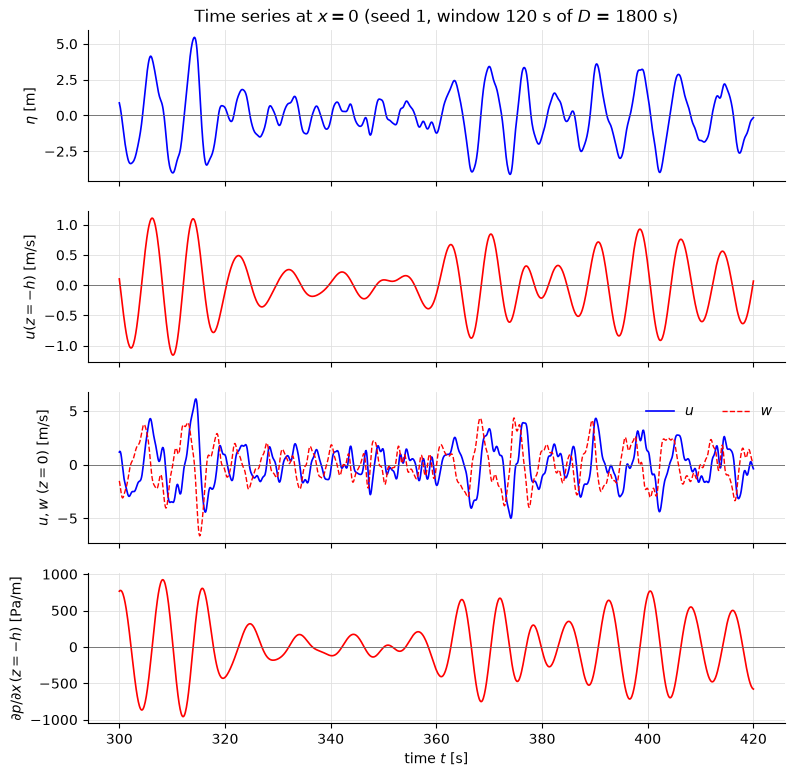

In [8]:
#Select a window of 120 s and define the panels: (signal, y-label, colour)
win  = (t >= 300) & (t <= 420)
rows = [("eta",      r"$\eta$ [m]", 'b'),
        ("u_bed",    r"$u(z=-h)$ [m/s]", 'r'),
        ("u_surf",   r"$u, w\ (z=0)$ [m/s]", 'b'),
        ("dpdx_bed", r"$\partial p/\partial x\,(z=-h)$ [Pa/m]", 'r')]


#Plot the time series under each other
fig, axes = plt.subplots(4, 1, figsize=(9, 9), sharex=True)
for ax, (key, label, col) in zip(axes, rows):
    ax.plot(t[win], ts[key][win], color=col, lw=1.2, label=r"$u$")
    ax.axhline(0, color="0.4", lw=0.6)
    ax.set_ylabel(label)
    style(ax, "")


#Add the vertical velocity near the surface to the third panel
axes[2].plot(t[win], ts["w_surf"][win], "--", color='r', lw=1.0, label=r"$w$")
axes[2].legend(frameon=False, loc="upper right", ncol=2)


#Add the title and the x-label and save the figure
axes[0].set_title(rf"Time series at $x = 0$ (seed {SEED}, window 120 s of $D$ = {D:.0f} s)")
axes[-1].set_xlabel(r"time $t$ [s]")
plt.savefig(OUT_DIR / "wave6_time_series.png", dpi=300, bbox_inches="tight")
plt.show()

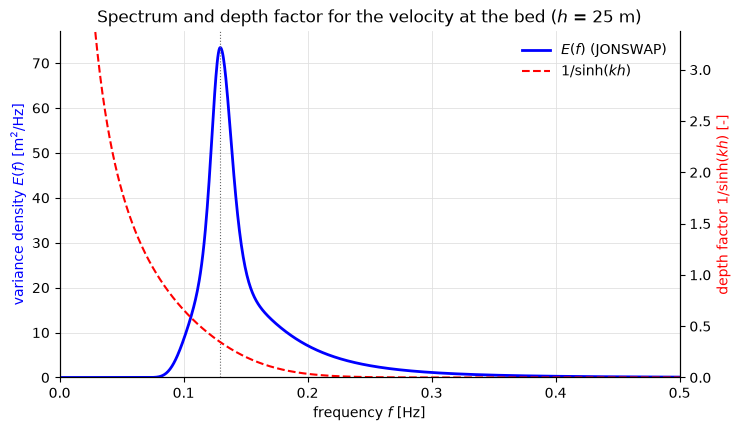

f = 0.130 Hz:  kh =  1.79,  1/sinh(kh) = 0.3451
f = 0.259 Hz:  kh =  6.75,  1/sinh(kh) = 0.0023
f = 0.400 Hz:  kh = 16.10,  1/sinh(kh) = 0.0000


In [9]:
#Calculate the depth factor 1/sinh(kh) for the velocity at the bed
f_line  = np.linspace(DF, F_MAX, 2000)    #[Hz]
k_line  = wave_number(2 * np.pi * f_line) #[rad/m]
depth_f = 1 / np.sinh(k_line * H_DEPTH)   #[-]


#Plot the spectrum E(f) on the left axis
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(f_line, E_jonswap(f_line, HS, fp), "-", color='b', lw=2, label=r"$E(f)$ (JONSWAP)")
ax.set_xlabel(r"frequency $f$ [Hz]")
ax.set_ylabel(r"variance density $E(f)$ [m$^2$/Hz]", color='b')
ax.set_xlim(0, 0.5)
ax.set_ylim(bottom=0)


#Plot the depth factor on the right axis
ax2 = ax.twinx()
ax2.plot(f_line, depth_f, "--", color='r', lw=1.5, label=r"$1/\sinh(kh)$")
ax2.set_ylabel(r"depth factor $1/\sinh(kh)$ [-]", color='r')
ax2.set_ylim(0, 1.05 * depth_f[f_line > 0.03].max())
ax2.spines["top"].set_visible(False)


#Mark the peak frequency, combine the legends and save the figure
ax.axvline(fp, color="0.4", lw=0.8, ls=":")
lines = ax.get_lines()[:1] + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], frameon=False, loc="upper right")
style(ax, r"Spectrum and depth factor for the velocity at the bed ($h$ = 25 m)")
ax.spines["right"].set_visible(True)
plt.savefig(OUT_DIR / "wave6_depth_factor.png", dpi=300, bbox_inches="tight")
plt.show()


#Print the depth factor at a few frequencies
for f_val in (fp, 2 * fp, 0.4):
    kf = wave_number(np.array([2 * np.pi * f_val]))[0]
    print(f"f = {f_val:.3f} Hz:  kh = {kf * H_DEPTH:5.2f},  1/sinh(kh) = {1 / np.sinh(kf * H_DEPTH):.4f}")

## Step 5 — Checks

**Check 1 — variance and $H_{m0}$.** The discrete components must contain the variance of the spectrum: $\sum a_i^2/2 = \sum E(f_i)\Delta f \approx m_0$. The variance of the time series must also match $m_0$, and $4\sqrt{m_0} \approx H_s = 7$ m. Here $m_0$ is integrated in the same way as in Wave Question 3 (trapezoid, 0.01–1.0 Hz, $\Delta f$ = 0.0005 Hz).

In [10]:
#Calculate m0 exactly as in Wave Question 3 (trapezoid rule, 0.01-1.0 Hz, df = 0.0005 Hz)
f_fine = np.arange(0.01, 1.0 + 0.0005 / 2, 0.0005)        #[Hz]
m0     = trapezoid(E_jonswap(f_fine, HS, fp), f_fine)    #[m2]


#Calculate the variance of the components and of the time series
var_comp = np.sum(a_i**2 / 2) #[m2]
var_eta  = ts["eta"].var()    #[m2]


#Print the results
print(f"m0 (Wave Question 3)  = {m0:.4f} m2")
print(f"sum a_i^2 / 2         = {var_comp:.4f} m2   ({100 * (var_comp / m0 - 1):+.3f} %)")
print(f"var(eta) time series  = {var_eta:.4f} m2   ({100 * (var_eta / m0 - 1):+.3f} %)")
print(f"4 sqrt(m0)            = {4 * np.sqrt(m0):.3f} m,   4 std(eta) = {4 * ts['eta'].std():.3f} m   (Hs = {HS} m)")

m0 (Wave Question 3)  = 3.0692 m2
sum a_i^2 / 2         = 3.0692 m2   (+0.000 %)
var(eta) time series  = 3.0692 m2   (+0.000 %)
4 sqrt(m0)            = 7.008 m,   4 std(eta) = 7.008 m   (Hs = 7.0 m)


$\sum a_i^2/2$ equals $m_0$, and so does the variance of the time series. With fixed amplitudes and $\Delta f = 1/D$, the components are exactly orthogonal over the duration $D$, so the variance of $\eta$ does not depend on the phases. $4\sqrt{m_0}$ returns $H_s = 7$ m. **The time series contains the right amount of energy.**

**Check 2 — duration and time step.**

In [11]:
#Check the duration against 1/Delta f and the time step against the Nyquist criterion
duration = t[-1] - t[0] + DT


#Print the results
print(f"Duration = {duration:.1f} s  <=  1/Delta f = {1 / DF:.1f} s :", duration <= 1 / DF + 1e-9)
print(f"Delta t  = {DT} s  <  1/(2 f_max) = {1 / (2 * F_MAX):.2f} s :", DT < 1 / (2 * F_MAX))

Duration = 1800.0 s  <=  1/Delta f = 1800.0 s : True
Delta t  = 0.1 s  <  1/(2 f_max) = 0.50 s : True


Both conditions hold. The series does not repeat within $D$, and the highest component (1 Hz) is resolved with 10 points per period, so there is no aliasing.

**Check 3 — dependence on the seed.** The calculation is repeated for 10 different seeds. With fixed amplitudes the rms values are set by the spectrum and should hardly change. The maxima depend on how the random phases happen to line up, so they should vary.

In [12]:
#Repeat the calculation for N_SEED different seeds and store rms, max and significant value
rows = []
for seed in range(1, N_SEED + 1):
    s = build_series(seed)
    row = {"seed": seed}

    for key in ("u_bed", "dpdx_bed", "u_surf", "w_surf"):
        row[f"{key} rms"] = s[key].std()
        row[f"{key} max"] = np.max(np.abs(s[key]))
        row[f"{key} sig"] = significant(s[key])

    row["speed_surf max"] = s["speed_surf"].max()
    rows.append(row)

seeds = pd.DataFrame(rows).set_index("seed")


#Create a panda with the mean, the spread and the coefficient of variation over the seeds and print it out
spread = pd.DataFrame({"mean": seeds.mean(), "std": seeds.std(), "CoV [%]": 100 * seeds.std() / seeds.mean()})
spread.style.format(precision=3)

,mean,std,CoV [%]
u_bed rms,0.431,0.000,0.000
u_bed max,1.501,0.161,10.724
u_bed sig,0.868,0.012,1.331
dpdx_bed rms,350.488,0.000,0.000
dpdx_bed max,1248.804,115.195,9.224
dpdx_bed sig,705.316,8.514,1.207
u_surf rms,1.869,0.000,0.000
u_surf max,7.137,0.544,7.618
u_surf sig,3.736,0.033,0.871
w_surf rms,1.819,0.000,0.000


The rms values are the same for every seed (CoV ≈ 0 %), because with fixed amplitudes the variance is fixed by the spectrum. The significant values vary only a little, by about 1 %. The **maxima vary clearly**, with a coefficient of variation of about 6–11 %, because a single extreme depends on how the phases happen to line up. A single 30-minute realisation therefore gives a reliable rms and significant value. The maximum, however, is only one sample of a random variable. For design, use the mean maximum over the seeds, or a value from a Rayleigh distribution.

**Check 4 — high frequencies do not reach the bed** (L5 slide 15). The velocity spectrum at depth $z$ is $S_u(f) = \left[\omega\,\cosh k(z+h)/\sinh kh\right]^2 E(f)$. At the bed, the factor $1/\sinh^2 kh$ removes the short waves almost completely, while at the surface ($\coth^2 kh \approx 1$) they remain. Below, the spectra estimated from the time series (Welch) are compared with this linear transfer.

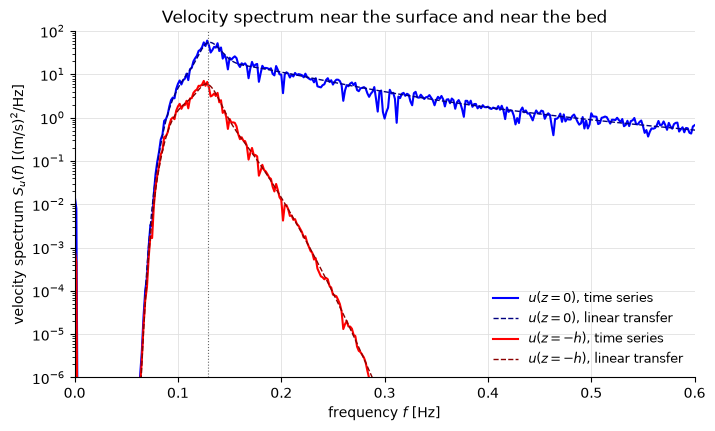

u near bed     :   0.0 % of the variance is above 2 fp = 0.26 Hz
u near surface :  21.6 % of the variance is above 2 fp = 0.26 Hz


In [13]:
#Estimate the velocity spectra from the time series (Welch, segments of 600 s)
nper = int(600 / DT)
f_w, S_bed  = welch(ts["u_bed"],  fs=1 / DT, nperseg=nper) #[(m/s)2/Hz]
_,   S_surf = welch(ts["u_surf"], fs=1 / DT, nperseg=nper) #[(m/s)2/Hz]


#Calculate the theoretical velocity spectra from the linear transfer
Su_bed_th  = (a_i * T_bed["u"])**2 / 2 / DF  #[(m/s)2/Hz]
Su_surf_th = (a_i * T_surf["u"])**2 / 2 / DF #[(m/s)2/Hz]


#Plot the velocity spectra at the bed and at the surface
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(f_w, S_surf, "-", color='b', lw=1.5, label=r"$u(z=0)$, time series")
ax.semilogy(f_i, Su_surf_th, "--", color="navy", lw=1, label=r"$u(z=0)$, linear transfer")
ax.semilogy(f_w, S_bed, "-", color='r', lw=1.5, label=r"$u(z=-h)$, time series")
ax.semilogy(f_i, Su_bed_th, "--", color="darkred", lw=1, label=r"$u(z=-h)$, linear transfer")
ax.axvline(fp, color="0.4", lw=0.8, ls=":")

ax.set_xlabel(r"frequency $f$ [Hz]")
ax.set_ylabel(r"velocity spectrum $S_u(f)$ [(m/s)$^2$/Hz]")
ax.set_xlim(0, 0.6)
ax.set_ylim(1e-6, 1e2)
ax.legend(frameon=False, loc="lower right", fontsize=9)
style(ax, "Velocity spectrum near the surface and near the bed")
plt.savefig(OUT_DIR / "wave6_velocity_spectra.png", dpi=300, bbox_inches="tight")
plt.show()


#Calculate and print the fraction of the velocity variance above 2 fp at the bed and at the surface
hi = f_i > 2 * fp
for name, S in (("bed", Su_bed_th), ("surface", Su_surf_th)):
    print(f"u near {name:8s}: {100 * S[hi].sum() / S.sum():5.1f} % of the variance is above 2 fp = {2 * fp:.2f} Hz")

At the bed the velocity spectrum drops off steeply above the peak. Almost all of the energy above $2f_p$ is gone, while at the surface a clear tail remains. The time series of $u$ at the bed is therefore **smoother and more regular** than the one at the surface (see the plot in Step 4), and its mean period is longer. The Welch estimate follows the linear transfer, which confirms the synthesis.

**Check 5 — other remarks.**
- **Surface:** the value at $z = 0$ is the linear-theory value at still water level. Above $z = 0$ (in the crests) linear theory is not valid. A stretching method (e.g. Wheeler) or non-linear theory would be needed there, so the maximum crest velocity is underestimated. For these steep waves ($ka = 0.25$, $H_s/h = 0.28$) non-linear effects (higher, sharper crests) also make the real maxima larger than the linear ones.
- **Current:** $U = 1.5$ m/s is neglected (see the assumptions). With current, the total velocity near the bed and near the surface would be roughly $U + u$, and the wave kinematics would change through the Doppler shift.
- **Amplitudes:** fixed amplitudes $a_i = \sqrt{2E\Delta f}$ were used. That is why the variance matches $m_0$ exactly for every seed. With random (Rayleigh) amplitudes the rms values would also vary between seeds.

## Step 6 — Summary

In [14]:
#Define a function that collects rms, significant value and maxima of one quantity
def summary_column(key):
    return [table.loc[names[key], "std (rms)"],
            table.loc[names[key], "significant (1/3 peaks)"],
            np.max(np.abs(ts[key])),
            spread.loc[f"{key} max", "mean"]]


#Collect the columns; the magnitude sqrt(u2+w2) has its rms about zero and no significant value
speed = ts["speed_surf"]
summary = pd.DataFrame({
    "u near bed [m/s]":               summary_column("u_bed"),
    "dp/dx near bed [Pa/m]":          summary_column("dpdx_bed"),
    "u near surface [m/s]":           summary_column("u_surf"),
    "w near surface [m/s]":           summary_column("w_surf"),
    "sqrt(u2+w2) near surface [m/s]": [np.sqrt(np.mean(speed**2)), np.nan, speed.max(), spread.loc["speed_surf max", "mean"]],
}, index=["rms", "significant (1/3 peaks)", f"max |.| (seed {SEED})", f"max |.| (mean of {N_SEED} seeds)"])


#Print the table
summary.style.format(precision=3, na_rep="-")

,u near bed [m/s],dp/dx near bed [Pa/m],u near surface [m/s],w near surface [m/s],sqrt(u2+w2) near surface [m/s]
rms,0.431,350.488,1.869,1.819,2.608
significant (1/3 peaks),0.860,703.534,3.721,3.560,-
max |.| (seed 1),1.465,1249.806,6.889,6.637,7.150
max |.| (mean of 10 seeds),1.501,1248.804,7.137,6.782,7.361
